f(x0, x1, x2) = 3.x0 + 2.x1 + x2 - 4.x0.x1 - 2.x1.x2

| x0.x1.x2 | QUBO value |
| :--- | :--- |
| 000 | 0 |
| 001 | 1 |
| 010 | 2 |
| 011 | 1 |
| 100 | 3 |
| 101 | 4 |
| 110 | 1 |
| 111 | 0 |

| Operation | Quantum gate | Purpose |
| :--- | :--- | :--- |
| Superposition | h() | Generate all candidate solutions |
| x_i | p(θ) | Apply phase to state where x_i=1 |
| x_i.x_j| cp(θ) | Apply phase when both bits are 1 |
| Mixer | rx(θ) | Mix candidate solutions |

One layer of QAOA = cost unitary + mixer unitary

Cost unitary: U_C(γ)=e^{-i.γ.f(x)}

U_C(γ) = P_0(-3.γ). P_1(-2.γ). P_2(-γ) x CP_{01}(-4.γ). CP_{12}(-2.γ)

P and CP are phase and controlled-phase gates.

In [9]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from scipy.optimize import minimize
from collections import Counter
from qiskit.visualization import plot_histogram

In [10]:
def cost_unitary(qc, gamma):
    # Uc = exp(+i * gamma * f(x))
    # Positive sign because we want MAXIMUM

    qc.p(3 * gamma, 0)       # 3*x0
    qc.p(2 * gamma, 1)       # 2*x1
    qc.p(1 * gamma, 2)       # x2

    qc.cp(-4 * gamma, 0, 1)  # -4*x0*x1
    qc.cp(-2 * gamma, 1, 2)  # -2*x1*x2

    return qc

def mixer_unitary(qc, beta):
    qc.rx(2 * beta, 0)
    qc.rx(2 * beta, 1)
    qc.rx(2 * beta, 2)

    return qc

In [11]:
p = 2  # Number of QAOA layers

def create_qaoa_circuit(params, measure=False):
    qc = QuantumCircuit(3)

    # Initial superposition
    qc.h([0, 1, 2])

    # Apply p cost and mixer layers
    for layer in range(p):

        gamma = params[layer]
        beta = params[p + layer]

        cost_unitary(qc, gamma)
        mixer_unitary(qc, beta)

    if measure:
        qc.measure_all()

    return qc

In [12]:
# Qiskit uses q0 as the least significant bit.
# Therefore, integer i represents:
# x0 = bit 0, x1 = bit 1, x2 = bit 2

def f(x0, x1, x2):
    return 3*x0 + 2*x1 + x2 - 4*x0*x1 - 2*x1*x2

costs = np.array([
    f((i >> 0) & 1,
      (i >> 1) & 1,
      (i >> 2) & 1)
    for i in range(8)
])

In [13]:
def objective(params):
    qc = create_qaoa_circuit(params)
    state = Statevector.from_instruction(qc)
    probabilities = state.probabilities()
    expected_value = np.dot(probabilities, costs)

    # scipy minimizes, so negate for maximization
    return -expected_value

In [14]:
best_result = None
np.random.seed(42)

for _ in range(5):
    initial_params = np.random.uniform(
        0, 2*np.pi, 2*p
    )

    result = minimize(
        objective,
        initial_params,
        method="COBYLA",
        options={"maxiter": 500, "rhobeg": 0.5}
    )

    if best_result is None or result.fun < best_result.fun:
        best_result = result


optimal_params = best_result.x

print("Optimal gamma:", optimal_params[:p])
print("Optimal beta:", optimal_params[p:])
print("Maximum expected QUBO value:", -best_result.fun)

Optimal gamma: [4.67743978 4.6673285 ]
Optimal beta: [0.7502324  5.20548648]
Maximum expected QUBO value: 3.011682664665155



Optimized QAOA Circuit:


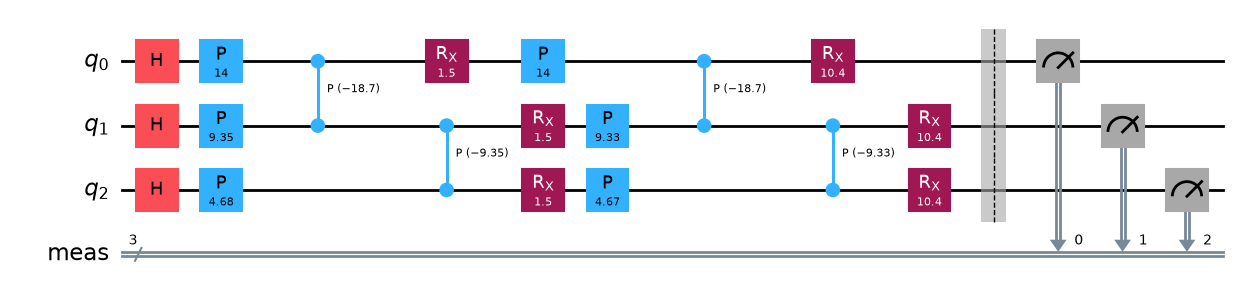

In [15]:
final_qc = create_qaoa_circuit(
    optimal_params,
    measure=True
)

print("\nOptimized QAOA Circuit:")
display(final_qc.draw("mpl"))

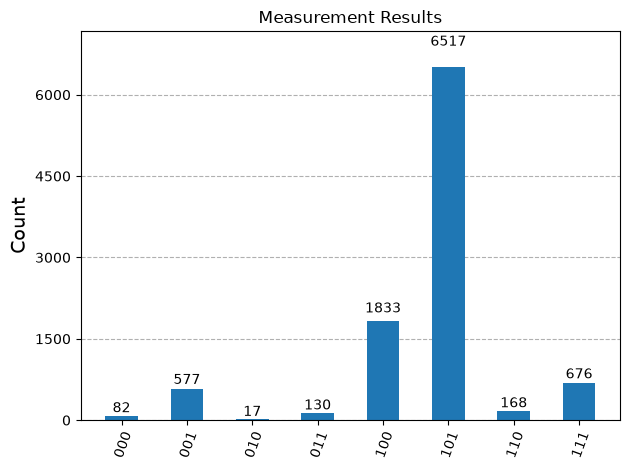

In [19]:
backend = AerSimulator()
compiled = transpile(final_qc, backend)
job = backend.run(compiled, shots=10000)
counts = job.result().get_counts()
plot_histogram(counts, title="Measurement Results")

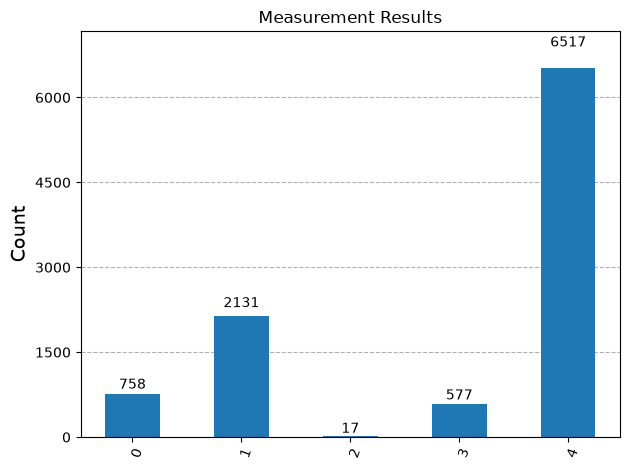

In [22]:
results = {}

for bitstring, count in counts.items():
    # Remove spaces and reverse Qiskit's
    # classical bitstring ordering

    x = bitstring.replace(" ", "")[::-1]
    x0, x1, x2 = map(int, x)
    value = f(x0, x1, x2)
    results[value] = results.get(value, 0) + count

plot_histogram(results, title="Measurement Results")